In [3]:
import os
import numpy as np
import pandas as pd

df = pd.read_csv('works.csv').dropna(subset=['title', 'abstract']).reset_index(drop=True)

if os.path.exists('emb_bge_m3.npy'):
    emb = np.load('emb_bge_m3.npy')
    print('저장된 벡터를 불러왔어요')
else:
    from sentence_transformers import SentenceTransformer
    m_full = SentenceTransformer('BAAI/bge-m3', device='cuda')
    m_full.max_seq_length = 256
    emb = m_full.encode((df['title'] + '. ' + df['abstract']).tolist(), batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    np.save('emb_bge_m3.npy', emb)
    print('새로 계산해서 저장했어요')

assert len(df) == emb.shape[0]
print('논문 수:', len(df), '| 벡터 차원:', emb.shape[1])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/920 [00:00<?, ?it/s]

새로 계산해서 저장했어요
논문 수: 29417 | 벡터 차원: 1024


# 임베딩 실습 정리: 수산·해양 논문 29,417편의 의미 군집

> 무료 임베딩 모델로 논문을 벡터로 바꾸고, 벡터끼리의 거리로 토픽이 모이는지 확인합니다.

## 전체 흐름

```
논문 제목 + 초록
   ↓  임베딩 (bge-m3, 1,024차원)
벡터 29,417개
   ├─→ 코사인 유사도 · 최근접 이웃   : 거리를 직접 계산
   ├─→ PCA · UMAP 그림             : 모양을 눈으로 확인
   ├─→ 군집화 (K-평균 · HDBSCAN · 계층적) → ARI : 토픽과 얼마나 맞는지 숫자로 확인
   ├─→ 덴드로그램                   : 군집이 합쳐지는 순서 확인
   └─→ 모델 비교 (KURE · bge-m3 · e5 · MiniLM) : 같은 조건에서 모델만 바꿔 비교
```

## 목차

1. 용어 정의
2. 데이터
3. 준비 (불러오기)
4. 코사인 유사도
5. 최근접 이웃
6. 2차원 그림 (PCA · UMAP)
7. 군집화와 ARI
8. 덴드로그램
9. 모델 비교
10. 단어 실습 (36단어)
11. 결론과 한계

## 1. 용어 정의

| 용어 | 뜻 |
|---|---|
| **임베딩** | 글을 숫자 여러 개(벡터)로 바꾼 것. 뜻이 비슷한 글은 벡터도 가깝게 나옵니다. |
| **코사인 유사도** | 두 벡터 방향이 얼마나 같은지. 1에 가까울수록 비슷하고, 벡터 길이를 1로 맞추면 내적과 같습니다. |
| **코사인 거리** | 1 − 코사인 유사도. 작을수록 가깝습니다. |
| **최근접 이웃** | 기준 벡터와 가장 가까운 벡터 k개. |
| **PCA** | 분산이 큰 방향 2개로 투영. 빠르지만 복잡한 군집 구조는 잘 드러나지 않습니다. |
| **UMAP** | 이웃 관계를 살려 2차원 좌표를 새로 만듦. 군집이 잘 보이지만 그림 속 간격은 실제 거리와 정확히 같지 않습니다. |
| **K-평균** | 군집 수 k를 정하고 가장 가까운 중심에 배정. |
| **계층적 군집** | 가까운 군집끼리 하나씩 합쳐 가는 방법. 덴드로그램으로 과정을 그립니다. |
| **HDBSCAN** | 밀도가 높은 곳을 군집으로, 낮은 점은 이상치(−1)로 분류. 군집 수를 미리 정하지 않습니다. |
| **ARI** | 군집이 실제 라벨과 얼마나 같은지. 1이면 일치, 0 근처면 무작위 수준입니다. |
| **토픽** | OpenAlex가 논문마다 자동으로 붙인 주제 라벨. 이 실습의 정답 범주입니다. |

## 2. 데이터

- **출처**: [OpenAlex](https://openalex.org) (메타데이터 CC0)
- **수집 기준**: 주 토픽이 아래 6개 중 하나, 2015~2025년, 초록 있음, 토픽당 최대 5,000편
- **빈 칸 제거 후**: **29,417편**

| 토픽 | 논문 수 |
|---|---:|
| Fisheries and Aquaculture | 5,000 |
| Ichthyology and Marine Biology | 5,000 |
| Cephalopods and Marine Biology | 4,418 |
| Marine and Coastal Ecosystems | 5,000 |
| Food Industry and Aquatic Biology | 5,000 |
| Coastal and Marine Management | 5,000 |

> 토픽은 서로 겹치는 부분이 있어요 (예: 양식과 식품 가공). 그래서 군집이 완벽하게 나뉘지 않는 것이 정상입니다.

## 3. 준비

`works.csv`와 `emb_bge_m3.npy`를 Colab에 올린 뒤 아래 셀을 실행합니다.

그래프 글씨가 깨지지 않도록 `koreanize-matplotlib`을 먼저 설치합니다.

In [4]:
!pip -q install koreanize-matplotlib umap-learn

import koreanize_matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import umap

plt.rcParams['figure.dpi'] = 120

df = pd.read_csv('works.csv').dropna(subset=['title', 'abstract']).reset_index(drop=True)
emb = np.load('emb_bge_m3.npy')
assert len(df) == emb.shape[0]
print('논문 수:', len(df), '| 벡터 차원:', emb.shape[1])

논문 수: 29417 | 벡터 차원: 1024


## 4. 코사인 유사도

벡터를 정규화했기 때문에 **내적이 곧 코사인 유사도**입니다.

아래 그림은 토픽 순서로 정렬한 120편의 유사도 행렬입니다.

> 밝은 정사각형 블록 → 같은 토픽끼리 가깝다는 뜻
> 전체 평균 코사인 **0.439** → 아무 두 논문을 골라도 대략 이 정도 값이 나옵니다

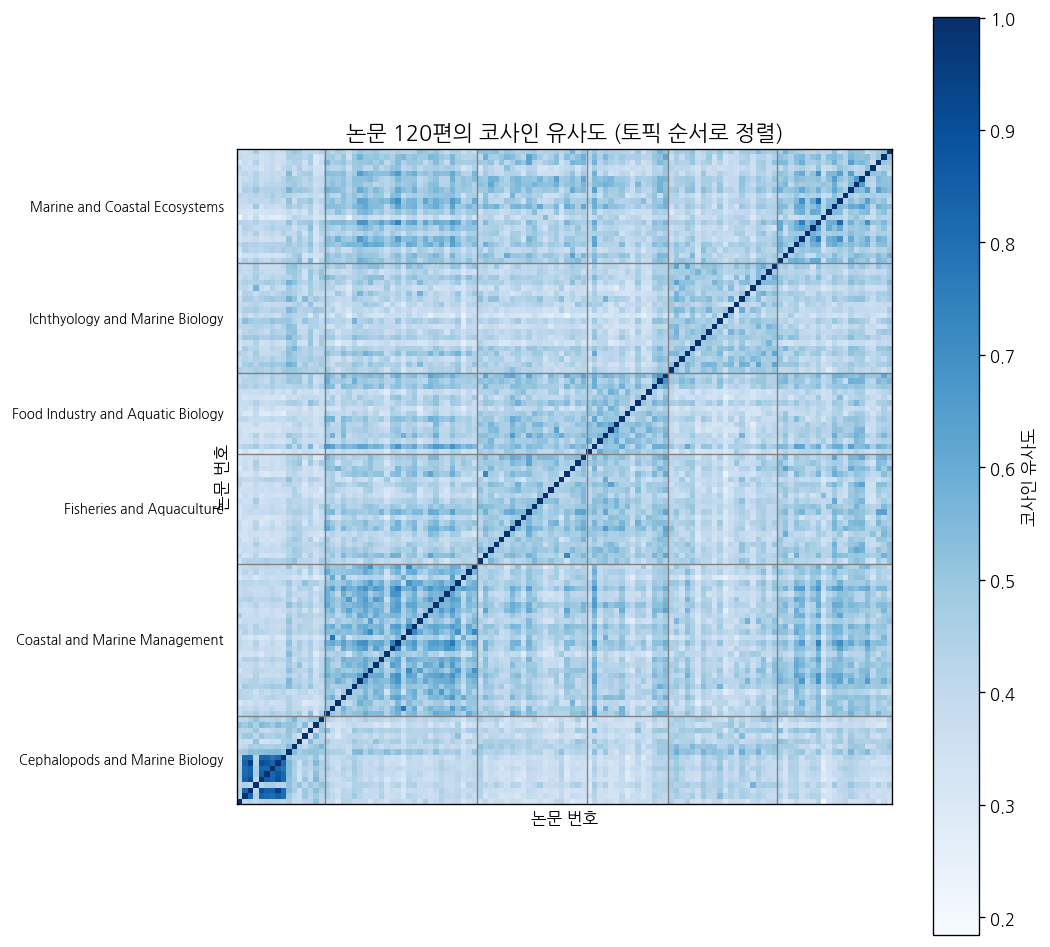

In [20]:
order = df.sort_values('group').sample(120, random_state=0).sort_values('group')
idx = order.index.values
e = emb[idx]
sim = e @ e.T
groups_s = order['group'].values

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap='Blues', origin='lower')
fig.colorbar(im, ax=ax, label='코사인 유사도')

# 토픽이 바뀌는 지점에 경계선 긋기
boundaries = [i for i in range(1, len(groups_s)) if groups_s[i] != groups_s[i - 1]]
for b in boundaries:
    ax.axhline(b - 0.5, color='gray', lw=0.8)
    ax.axvline(b - 0.5, color='gray', lw=0.8)

# 토픽 이름은 구간 가운데에 표시
starts = [0] + boundaries
ends = boundaries + [len(groups_s)]
for s, e_ in zip(starts, ends):
    mid = (s + e_ - 1) / 2
    ax.text(-3, mid, groups_s[s], ha='right', va='center', fontsize=8)

ax.set_title('논문 120편의 코사인 유사도 (토픽 순서로 정렬)', fontsize=13)
ax.set_xlabel('논문 번호')
ax.set_ylabel('논문 번호')
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

## 5. 최근접 이웃

기준 논문과 가장 가까운 논문 4편을 찾습니다.

> 기준: 양식 정책 논문 → 이웃 4편 모두 양식·해양 정책 논문
> 토픽이 달라도 주제가 가까우면 이웃이 될 수 있습니다 (0.804).

In [6]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=5, metric='cosine').fit(emb)
q = 100
dist, nb = nn.kneighbors(emb[[q]])

print('기준:', df.title[q][:80], f'[{df.group[q]}]')
for d, j in zip(dist[0][1:], nb[0][1:]):
    print(f'  {1 - d:.3f}  {df.title[j][:80]}  [{df.group[j]}]')

기준: Aquaculture policy: Designing licenses for environmental regulation [Fisheries and Aquaculture]
  0.804  Planning and licensing for marine aquaculture  [Coastal and Marine Management]
  0.776  Technological innovations promoting sustainable salmon (Salmo salar) aquaculture  [Fisheries and Aquaculture]
  0.750  Serving the industry or undermining the regulatory system? The use of special pu  [Fisheries and Aquaculture]
  0.748  Implications of Entry Restrictions to Address Externalities in Aquaculture: The   [Fisheries and Aquaculture]


## 6. 2차원 그림: PCA vs UMAP

1,024차원을 2차원으로 줄여 같은 300편씩을 그렸습니다.

> **PCA** → 토픽들이 크게 겹침 (주황·파랑 정도만 구분)
> **UMAP** → 주황, 빨강, 보라, 파랑이 각각 뭉침. 초록(양식)과 갈색(생태계)은 가운데에서 섞임
>
> 그림의 간격은 실제 거리와 정확히 같지 않으니, **뭉침 여부**만 보세요.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


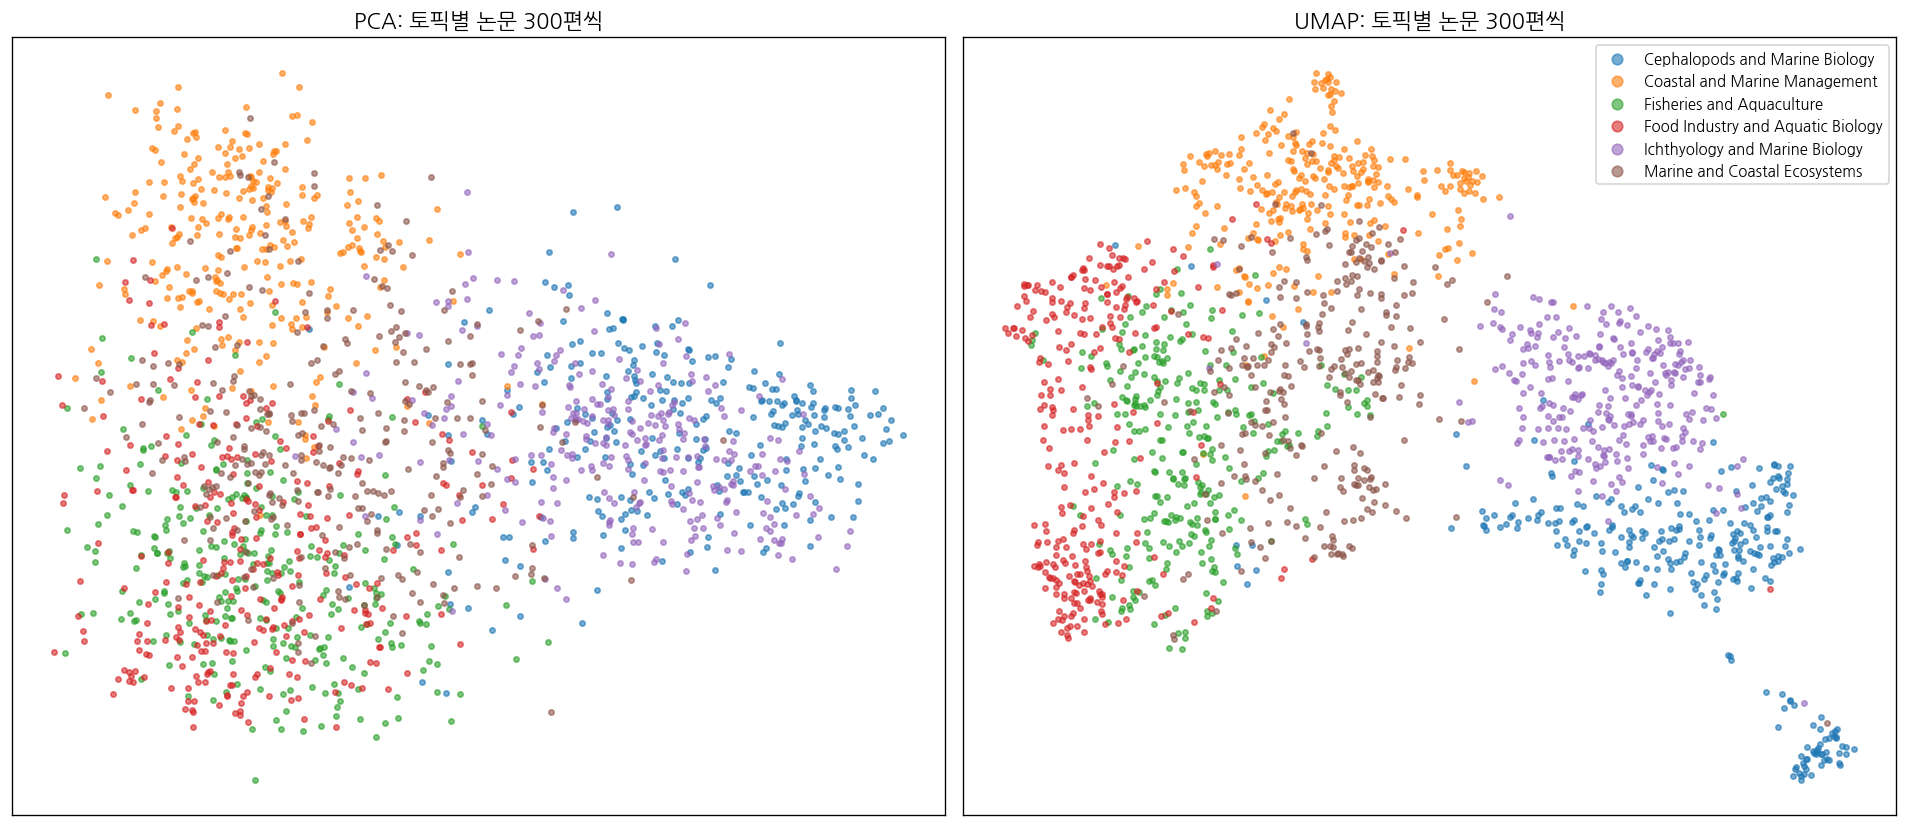

In [7]:
sub = df.groupby('group', group_keys=False).sample(300, random_state=0)
e_sub = emb[sub.index.values]

xy_pca = PCA(n_components=2, random_state=0).fit_transform(e_sub)
xy_umap = umap.UMAP(n_neighbors=15, min_dist=0.3, metric='cosine', random_state=0).fit_transform(e_sub)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, xy, title in zip(axes, [xy_pca, xy_umap], ['PCA', 'UMAP']):
    for g in sub['group'].unique():
        m = (sub['group'] == g).values
        ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=g)
    ax.set_title(f'{title}: 토픽별 논문 300편씩', fontsize=13)
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(loc='upper right', fontsize=9, markerscale=2)
plt.tight_layout()
plt.show()

## 7. 군집화와 ARI

전체 29,417편을 K-평균(k=6)으로 나누고, 토픽과 비교합니다.

> 표의 한 행 → 토픽 하나가 어느 군집에 들어갔는지
> 진할수록 많이 들어간 칸

| 방법 | ARI | 해석 |
|---|---:|---|
| **K-평균 (k=6)** | **0.420** | 가장 잘 나뉨 |
| K-평균 (k=4 / 5 / 8) | 0.389 / 0.404 / 0.477 | 군집이 많을수록 높아짐 |
| HDBSCAN (50차원) | 0.022 | 군집 3개, 이상치 9,995편 |
| 계층적 군집 (3,000편) | 0.000 | 한 덩어리로 몰림 |

K-평균 ARI: 0.42


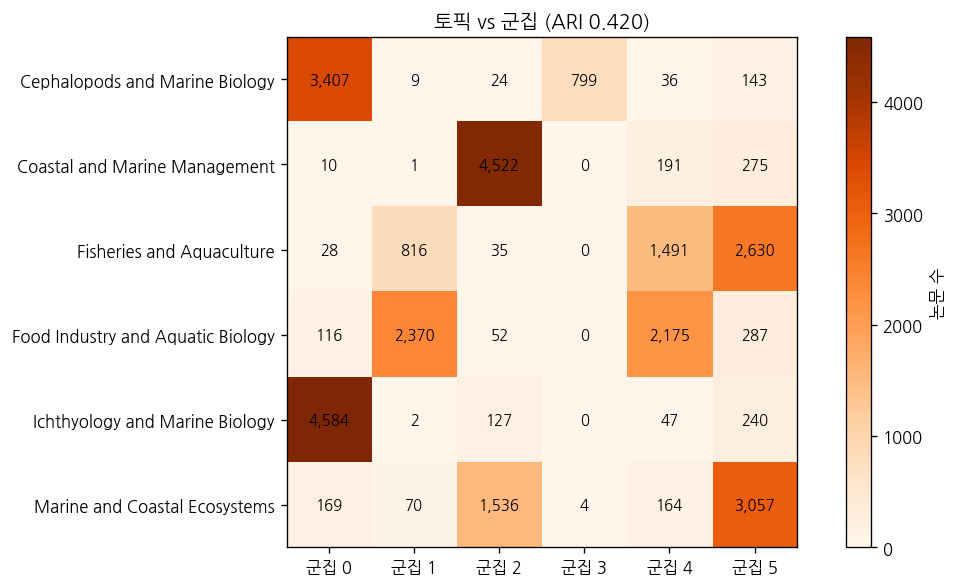

In [8]:
km = KMeans(n_clusters=6, n_init=10, random_state=0).fit_predict(emb)
ari = adjusted_rand_score(df['group'], km)
print('K-평균 ARI:', round(ari, 3))

ct = pd.crosstab(df['group'], km)
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(ct.values, cmap='Oranges')
ax.set_xticks(range(ct.shape[1]), [f'군집 {c}' for c in ct.columns])
ax.set_yticks(range(ct.shape[0]), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f'{ct.values[i, j]:,}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='논문 수')
ax.set_title(f'토픽 vs 군집 (ARI {ari:.3f})')
plt.tight_layout()
plt.show()

## 8. 덴드로그램

계층적 군집이 논문을 합치는 순서를 나무 모양으로 그립니다.

> 세로축 = 합쳐질 때의 코사인 거리
> 아래에서 일찍 합쳐진 가지 → 서로 가까운 논문
> 0.6~0.7에서 합쳐지는 큰 가지 → 큰 덩어리의 경계
>
> 뚜렷한 몇 개 덩어리로 끊어지지 않고 **연속적으로 이어집니다** → 토픽 경계가 뚜렷하지 않다는 뜻

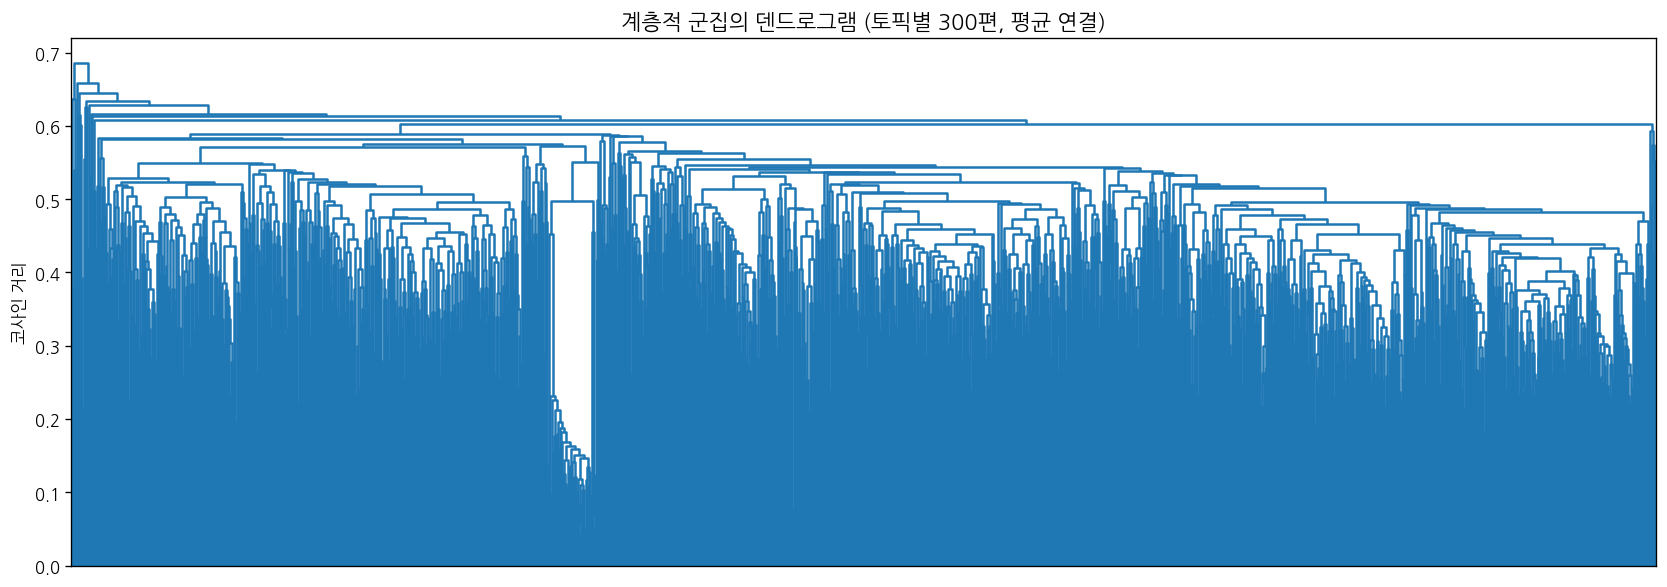

In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(e_sub, method='average', metric='cosine')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=0, above_threshold_color='tab:blue')
plt.ylabel('코사인 거리')
plt.title('계층적 군집의 덴드로그램 (토픽별 300편, 평균 연결)', fontsize=13)
plt.tight_layout()
plt.show()

## 9. 모델 비교

같은 3,000편 샘플에서 임베딩 모델만 바꿔 K-평균 ARI를 비교했습니다.

| 모델 | 차원 | ARI |
|---|---:|---:|
| KURE-v1 | 1,024 | **0.413** |
| bge-m3 | 1,024 | 0.408 |
| multilingual-e5-small | 384 | 0.353 |
| paraphrase-multilingual-MiniLM-L12-v2 | 384 | 0.317 |

> 1,024차원 모델 → 384차원 모델보다 높음
> KURE와 bge-m3는 사실상 동점
> 샘플을 바꾸면 순위가 달라질 수 있어요

## 10. 단어 실습 (36단어)

원래 노트북의 단어 실습을 수산·해양 단어 36개로 같은 순서대로 따라 했습니다. 범주마다 6개씩입니다.

| 범주 | 단어 |
|---|---|
| 어류 | 고등어, 갈치, 참치, 연어, 광어, 명태 |
| 갑각·연체류 | 대게, 새우, 전복, 가리비, 홍합, 문어 |
| 해조류 | 미역, 다시마, 김, 톳, 파래, 청각 |
| 어선·어구 | 그물, 통발, 낚싯대, 어선, 유자망, 부표 |
| 해양 환경 | 수온, 염분, 해류, 플랑크톤, 적조, 파도 |
| 해양 자원 | 석유, 천연가스, 메탄하이드레이트, 망간, 해상풍력, 조력발전 |

In [10]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'

words_by_group = {
    '어류': ['고등어', '갈치', '참치', '연어', '광어', '명태'],
    '갑각·연체류': ['대게', '새우', '전복', '가리비', '홍합', '문어'],
    '해조류': ['미역', '다시마', '김', '톳', '파래', '청각'],
    '어선·어구': ['그물', '통발', '낚싯대', '어선', '유자망', '부표'],
    '해양 환경': ['수온', '염분', '해류', '플랑크톤', '적조', '파도'],
    '해양 자원': ['석유', '천연가스', '메탄하이드레이트', '망간', '해상풍력', '조력발전'],
}
words = [w for ws in words_by_group.values() for w in ws]
groups = [g for g, ws in words_by_group.items() for _ in ws]
n = len(words)

word_model = SentenceTransformer('BAAI/bge-m3', device=device)
w_emb = word_model.encode(words, normalize_embeddings=True)
print('단어 수:', n, '| 벡터 모양:', w_emb.shape)

sim = w_emb @ w_emb.T
same = [sim[i, j] for i in range(n) for j in range(n) if i != j and groups[i] == groups[j]]
diff = [sim[i, j] for i in range(n) for j in range(n) if groups[i] != groups[j]]
print(f'같은 범주 평균: {np.mean(same):.3f} | 다른 범주 평균: {np.mean(diff):.3f}')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

단어 수: 36 | 벡터 모양: (36, 1024)
같은 범주 평균: 0.431 | 다른 범주 평균: 0.402


### 10-1. 코사인 유사도

> 같은 범주 평균 **0.431**, 다른 범주 평균 **0.402** → 차이가 작아요
> 연어↔광어, 고등어↔참치, 낚싯대↔어선 같은 쌍이 진하게 보여요
> 범주 경계가 블록으로 뚜렷하지 않아요

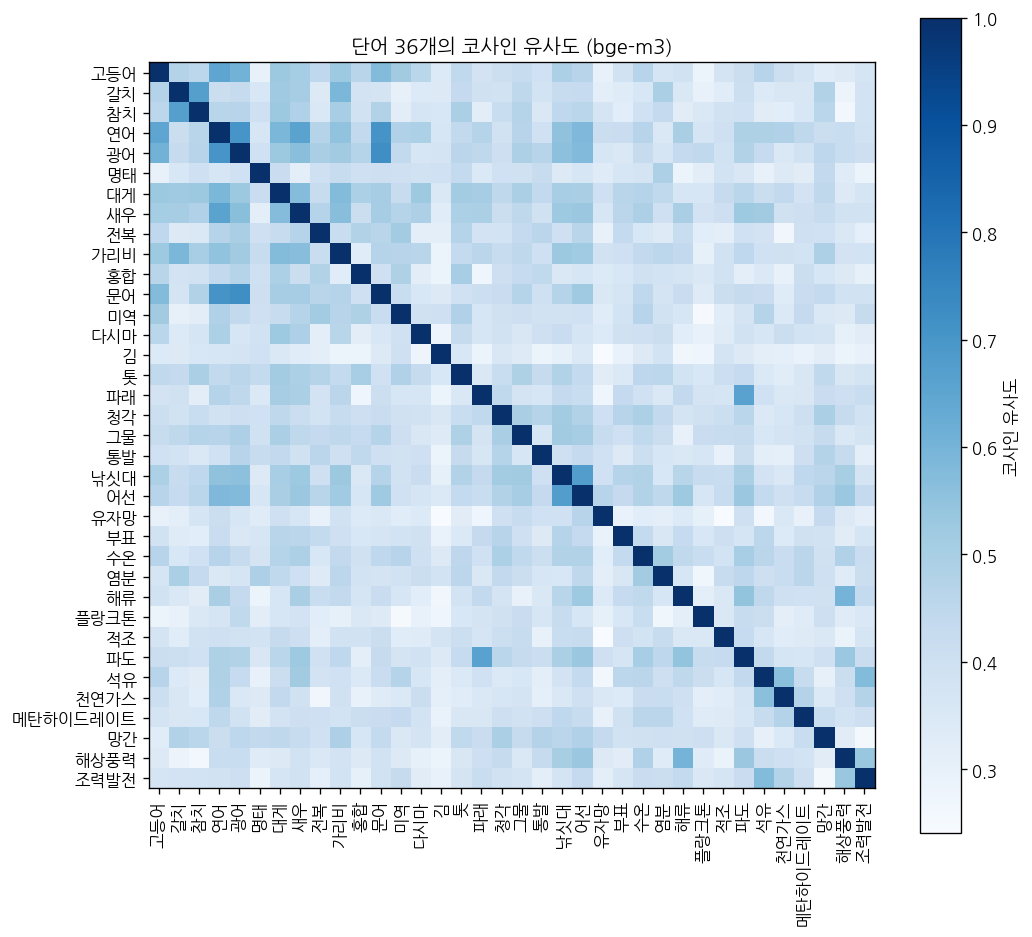

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap='Blues')
ax.set_xticks(range(n), words, rotation=90)
ax.set_yticks(range(n), words)
fig.colorbar(im, ax=ax, label='코사인 유사도')
ax.set_title('단어 36개의 코사인 유사도 (bge-m3)')
plt.tight_layout()
plt.show()

### 10-2. 최근접 이웃

> 같은 범주 이웃 비율 **40/108 (약 37%)**, 무작위 기준 약 14%
> **조력발전**: 이웃 3개가 모두 해양 자원 → 주제가 뚜렷한 단어는 잘 모임
> **해조류(미역·다시마·톳·청각)**: 이웃이 다른 범주로 흩어짐
> **파래 ↔ 파도**: 첫 토큰 ▁파 가 같아서 가까워짐 → 단어 하나에서는 글자 겹침이 영향을 줌

In [12]:
from sklearn.neighbors import NearestNeighbors

nn_w = NearestNeighbors(n_neighbors=4, metric='cosine').fit(w_emb)
dist, idx = nn_w.kneighbors(w_emb)

rows = []
for i, w in enumerate(words):
    nbrs = [f'{words[j]}({1 - d:.2f})' for d, j in zip(dist[i][1:], idx[i][1:])]
    same_cnt = sum(groups[j] == groups[i] for j in idx[i][1:])
    rows.append([w, groups[i]] + nbrs + [f'{same_cnt}/3'])

nn_table = pd.DataFrame(rows, columns=['단어', '범주', '이웃 1', '이웃 2', '이웃 3', '같은 범주'])
print('같은 범주 이웃 비율:', round(sum(int(s.split('/')[0]) for s in nn_table['같은 범주']) / (3 * n), 3))
nn_table

같은 범주 이웃 비율: 0.37


,단어,범주,이웃 1,이웃 2,이웃 3,같은 범주
0,고등어,어류,연어(0.65),광어(0.60),문어(0.57),2/3
1,갈치,어류,참치(0.67),가리비(0.59),대게(0.52),1/3
2,참치,어류,갈치(0.67),대게(0.53),가리비(0.50),1/3
3,연어,어류,문어(0.70),광어(0.70),새우(0.66),1/3
4,광어,어류,문어(0.72),연어(0.70),고등어(0.60),2/3
5,명태,어류,염분(0.49),망간(0.44),톳(0.44),0/3
6,대게,갑각·연체류,연어(0.59),가리비(0.57),새우(0.57),2/3
7,새우,갑각·연체류,연어(0.66),대게(0.57),가리비(0.56),2/3
8,전복,갑각·연체류,미역(0.51),광어(0.50),홍합(0.48),1/3
9,가리비,갑각·연체류,갈치(0.59),대게(0.57),새우(0.56),2/3


In [14]:
for w in ['파래', '파도', '사과', '사자']:
    print(w, '→', word_model.tokenizer.tokenize(w))

파래 → ['▁파', '래']
파도 → ['▁파', '도']
사과 → ['▁사', '과']
사자 → ['▁사', '자']


### 10-3. 새 단어 넣어 보기

> **오토바이 → 낚싯대, 어선**: 세트에 탈것 범주가 없어서 가장 가까운 배 종류(어선)로 감
> **멜론, 택시, 판사**: 과일·탈것·직업 범주가 없어서 가까운 이웃이 엉뚱함 (유사도 0.5 안팎)
>
> **정리**: 새 단어는 세트에 같은 의미 범주가 있을 때만 잘 찾음

In [13]:
new_words = ['멜론', '오토바이', '택시', '판사']
new_emb = word_model.encode(new_words, normalize_embeddings=True)
d2, i2 = nn_w.kneighbors(new_emb, n_neighbors=3)
for w, d, i in zip(new_words, d2, i2):
    print(w, '→', [f'{words[j]}({1 - x:.2f})' for x, j in zip(d, i)])

멜론 → ['수온(0.51)', '망간(0.49)', '메탄하이드레이트(0.48)']
오토바이 → ['낚싯대(0.51)', '어선(0.48)', '가리비(0.48)']
택시 → ['톳(0.49)', '대게(0.48)', '낚싯대(0.47)']
판사 → ['파도(0.52)', '청각(0.50)', '대게(0.49)']


### 10-4. 2차원 그림: PCA vs UMAP

> **PCA**: 전체적으로 겹침
> **UMAP**: 해양 자원(왼쪽 위), 어선·어구(오른쪽), 어류(가운데 아래)가 뭉쳐 보임
> 해조류와 갑각·연체류는 여러 곳에 흩어져 있음
>
> 단어가 적을 때는 UMAP이 구조를 더 잘 보여 줌 (n_neighbors=5로 설정)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


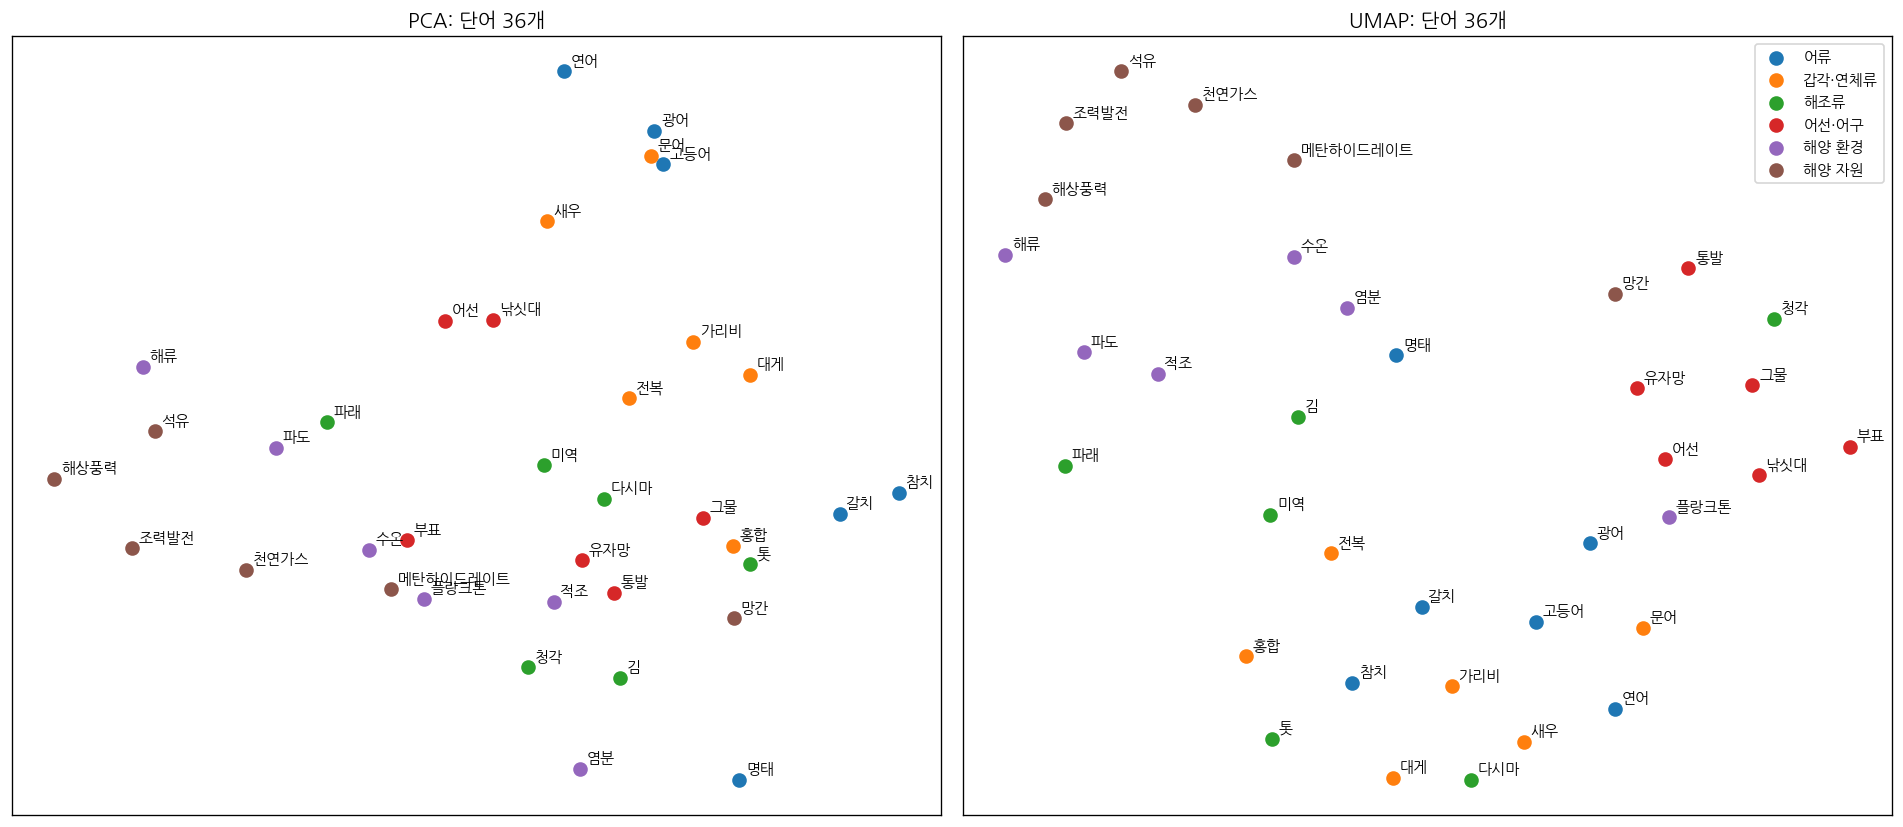

In [15]:
!pip -q install umap-learn
import umap
from sklearn.decomposition import PCA

xy_pca = PCA(n_components=2, random_state=0).fit_transform(w_emb)
xy_umap = umap.UMAP(n_neighbors=5, min_dist=0.3, metric='cosine', random_state=0).fit_transform(w_emb)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, xy, title in zip(axes, [xy_pca, xy_umap], ['PCA', 'UMAP']):
    for g in words_by_group:
        m = [k for k in range(n) if groups[k] == g]
        ax.scatter(xy[m, 0], xy[m, 1], s=60, label=g)
    for k, w in enumerate(words):
        ax.annotate(w, xy[k], fontsize=9, xytext=(4, 4), textcoords='offset points')
    ax.set_title(f'{title}: 단어 36개')
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 10-5. 군집화와 ARI

| 방법 | ARI | 해석 |
|---|---:|---|
| **K-평균 (k=6)** | **0.194** | 어선·어구(5/6), 해양 자원(4/6)은 잘 모임. 해조류는 흩어짐 |
| 계층적 군집 | 아래 셀 출력 | 덴드로그램과 함께 확인 |
| HDBSCAN | 아래 셀 출력 | 이상치가 얼마나 나오는지 확인 |

> 단어가 36개뿐이라 군집 결과가 쉽게 흔들림

In [16]:
from sklearn.cluster import AgglomerativeClustering, HDBSCAN

km_w = KMeans(n_clusters=6, n_init=10, random_state=0).fit_predict(w_emb)
agg_w = AgglomerativeClustering(n_clusters=6, metric='cosine', linkage='average').fit_predict(w_emb)
hdb_w = HDBSCAN(min_cluster_size=3).fit_predict(w_emb)

print('K-평균 ARI:', round(adjusted_rand_score(groups, km_w), 3))
print('계층적 군집 ARI:', round(adjusted_rand_score(groups, agg_w), 3))
print('HDBSCAN ARI:', round(adjusted_rand_score(groups, hdb_w), 3), '| 군집 수:', len(set(hdb_w) - {-1}), '| 이상치:', (hdb_w == -1).sum())
print(pd.crosstab(pd.Series(groups, name='범주'), pd.Series(km_w, name='군집')))

K-평균 ARI: 0.194
계층적 군집 ARI: 0.157
HDBSCAN ARI: 0.08 | 군집 수: 2 | 이상치: 21
군집      0  1  2  3  4  5
범주                      
갑각·연체류  0  1  0  3  2  0
어류      0  3  1  2  0  0
어선·어구   5  0  0  0  1  0
해양 자원   1  0  0  1  0  4
해양 환경   3  0  3  0  0  0
해조류     1  1  1  2  1  0


### 10-6. 덴드로그램

> 아래에서 먼저 합쳐진 가지 → 가까운 단어
> **어선·어구**(낚싯대, 어선, 그물, 부표)는 낮은 높이에서 먼저 묶임
> **어류**(고등어, 연어, 광어)도 0.3~0.4 근처에서 묶임. 문어는 갑각·연체류인데 함께 묶임
> 왼쪽 끝의 **김, 유자망**은 0.6 이상에서야 합쳐짐 → 다른 단어와 공통점이 거의 없음

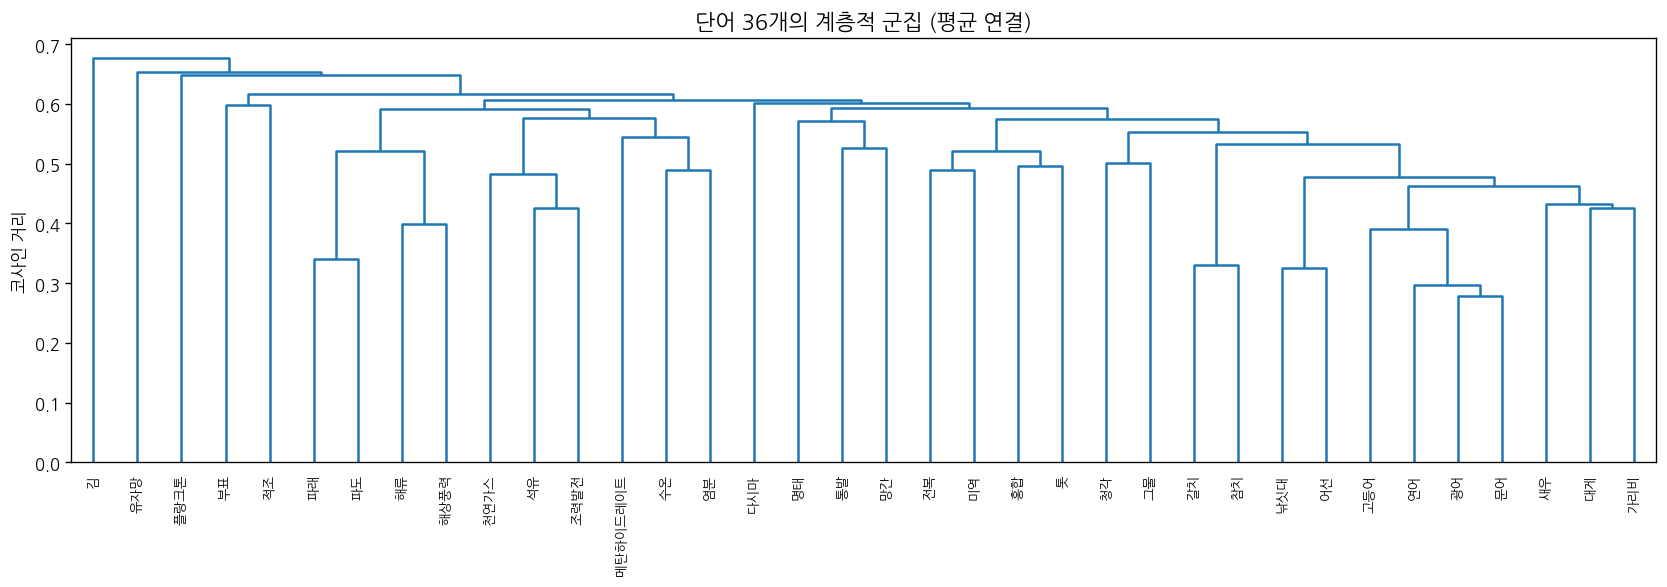

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z_w = linkage(w_emb, method='average', metric='cosine')
plt.figure(figsize=(14, 5))
dendrogram(Z_w, labels=words, leaf_rotation=90, color_threshold=0, above_threshold_color='tab:blue')
plt.ylabel('코사인 거리')
plt.title('단어 36개의 계층적 군집 (평균 연결)', fontsize=13)
plt.tight_layout()
plt.show()

### 10-7. 모델 교체 (단어 36개, K-평균 ARI)

| 모델 | ARI |
|---|---:|
| **bge-m3** | **0.194** |
| KURE-v1 | 0.101 |
| multilingual-e5-small | 0.054 |
| paraphrase-multilingual-MiniLM-L12-v2 | −0.033 |

> bge-m3가 단어 수준에서 가장 높음 (논문 수준에서는 KURE와 비슷했음)
> MiniLM은 0 아래 → 무작위 수준
> 단어 36개는 표본이 작아서 0.05 정도 차이는 의미가 약함

In [18]:
results = {'bge-m3': round(adjusted_rand_score(groups, km_w), 3)}

for name, prefix in [('intfloat/multilingual-e5-small', 'query: '),
                     ('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', ''),
                     ('nlpai-lab/KURE-v1', '')]:
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + w for w in words], normalize_embeddings=True)
    lab = KMeans(n_clusters=6, n_init=10, random_state=0).fit_predict(e)
    results[name.split('/')[-1]] = round(adjusted_rand_score(groups, lab), 3)
    del m
    torch.cuda.empty_cache()

for k, v in results.items():
    print(k, 'ARI:', v)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

bge-m3 ARI: 0.194
multilingual-e5-small ARI: 0.054
paraphrase-multilingual-MiniLM-L12-v2 ARI: -0.033
KURE-v1 ARI: 0.101


## 11. 결론과 한계

**결론**

1. 임베딩으로 논문을 토픽별로 묶으면 **어느 정도 잘 나뉩니다** (K-평균 ARI 0.42).
2. 모델은 **KURE-v1과 bge-m3**가 가장 좋았고, 1,024차원이 유리했습니다.
3. 군집 수를 늘리면 ARI가 올라갑니다 → 토픽 안에 세부 주제가 있습니다.
4. 밀도 기반(HDBSCAN)과 계층적 군집은 이 데이터에 잘 맞지 않았습니다.
5. 임베딩은 주제뿐 아니라 **언어**(인도네시아어 논문끼리 모임)에도 반응합니다.

**한계**

- 토픽 라벨은 자동으로 붙은 값이라 정답이 아닙니다.
- 토픽당 5,000편을 OpenAlex 순서대로 받아서 연도·학술지가 치우쳤을 수 있습니다.
- 모델 비교는 샘플 3,000편 한 번으로 했습니다.